# Laboratorio #9 — Series de tiempo y forecasting

**CC3092 · Deep Learning y Sistemas Inteligentes** — Universidad del Valle de Guatemala

**Nicolás Concuá y Esteban** · Guatemala, octubre de 2026

Repositorio: https://github.com/nicoCT04/Lab9-DL

Pronóstico *day-ahead* (H = 24 h) del consumo eléctrico horario de clientes de Portugal
(**ElectricityLoadDiagrams20112014**, UCI). El notebook construye el pipeline completo
**datos crudos → series horarias limpias → ventanas → tensores → modelo → backtest**, implementa un único
protocolo de evaluación `backtest(modelo)` con origen móvil diario (92 orígenes en oct–dic 2014) y compara
baselines estadísticos, modelos propios en PyTorch (MLP, DLinear, NLinear, LSTM, seq2seq) y modelos de librería.

## 0. Configuración del entorno

**Hardware:** Apple M4 Pro (GPU integrada, backend **MPS** de PyTorch). El código usa CUDA automáticamente si existe.

Variables de entorno opcionales:
- `LAB9_RETRAIN=1`: fuerza a reentrenar los modelos aunque existan pesos en caché (`data/modelos/`).
- `LAB9_QUICK=1`: prueba de humo (pocas épocas y pocas muestras por época).

In [1]:
# Descomenta para instalar dependencias (p. ej. en Colab):
# !pip install torch pandas numpy matplotlib statsforecast holidays pyarrow

In [2]:
import os, time, math, json, random, platform, warnings, urllib.request, zipfile
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
import holidays

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

# Semilla global para reproducibilidad.
SEED = 42
def fijar_semillas(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
fijar_semillas()

# Rutas robustas: funcionan tanto si se corre desde la raíz del lab como desde notebook/.
_EN_NOTEBOOK = os.path.basename(os.getcwd()) == 'notebook'
RAIZ    = '..' if _EN_NOTEBOOK else '.'
DATA    = os.path.join(RAIZ, 'data')        # datos crudos y cachés (no se versionan)
REPORTS = os.path.join(RAIZ, 'reports')     # figuras, tablas y pronósticos
MODELOS = os.path.join(DATA, 'modelos')     # pesos entrenados (caché)
for d in (DATA, REPORTS, MODELOS):
    os.makedirs(d, exist_ok=True)

QUICK   = os.environ.get('LAB9_QUICK') == '1'
RETRAIN = os.environ.get('LAB9_RETRAIN') == '1'

# Dispositivo: CUDA > MPS (Apple Silicon) > CPU.
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
try:
    import subprocess
    _cpu = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
except Exception:
    _cpu = ''
HARDWARE = f'{_cpu or platform.machine()} · {DEVICE.type.upper()}'
print('PyTorch', torch.__version__, '| dispositivo:', DEVICE, '| Python', platform.python_version())

PyTorch 2.15.0 | dispositivo: mps | Python 3.12.14


## 1. Datos

ElectricityLoadDiagrams20112014 (UCI): 370 clientes de Portugal, 2011–2014, potencia en **kW cada 15 minutos**.

| Elemento | Definición |
|---|---|
| Variable objetivo | consumo horario por cliente en kWh |
| Periodo | 2012-01-01 a 2014-12-31, solo clientes con datos completos desde 2012-01-01 |
| Horizonte | H = 24 h, pronóstico emitido a las 00:00 con datos hasta las 23:00 |
| Entrenamiento / validación / prueba | hasta 2014-06-30 / jul–sep 2014 / oct–dic 2014 (92 orígenes) |

In [3]:
# Descarga (solo la primera vez) y lectura del archivo crudo.
ZIP = os.path.join(DATA, 'electricity.zip')
TXT = os.path.join(DATA, 'LD2011_2014.txt')
RAW_PARQUET = os.path.join(DATA, 'raw_15min.parquet')
if not os.path.exists(RAW_PARQUET):
    if not os.path.exists(TXT):
        url = ('https://archive.ics.uci.edu/static/public/321/'
               'electricityloaddiagrams20112014.zip')
        urllib.request.urlretrieve(url, ZIP)
        zipfile.ZipFile(ZIP).extract('LD2011_2014.txt', DATA)
    raw = pd.read_csv(TXT, sep=';', decimal=',', index_col=0, parse_dates=True)
    raw.astype('float32').to_parquet(RAW_PARQUET)   # caché binaria: se lee ~20x más rápido
raw = pd.read_parquet(RAW_PARQUET)
print('crudo:', raw.shape, '|', raw.index.min(), '→', raw.index.max())

crudo: (140256, 370) | 2011-01-01 00:15:00 → 2015-01-01 00:00:00


### 1.1 Agregación a kWh por hora

Los valores están en **kW** (potencia media del intervalo de 15 min). La energía de un intervalo es
`kW × 0.25 h`, así que el consumo de una hora es la **suma de los 4 registros dividida entre 4** (kWh).
Se agrupan los registros `hh:00, hh:15, hh:30, hh:45` en la hora `hh`. ¿Por qué esa convención y no tomar cada marca
como fin del intervalo? Los días de cambio de horario lo delatan (sección 1.2): los registros en ~0 de marzo y los
duplicados de octubre son exactamente `01:00–01:45`, es decir, la hora de 1:00 a 2:00 que describe UCI.

In [4]:
INICIO, FIN = '2012-01-01 00:00', '2014-12-31 23:00'
horario = (raw.resample('h').sum() / 4.0).loc[INICIO:FIN]   # resample agrupa hh:00–hh:45 en la hora hh
print('panel horario 2012–2014:', horario.shape)

panel horario 2012–2014: (26304, 370)


### 1.2 Cambios de horario (DST)

El archivo no tiene horas repetidas ni faltantes: todos los días tienen 96 registros. Según la documentación de UCI,
en el **último domingo de marzo** (día de 23 h) los registros entre 1:00 y 2:00 valen ~0, y en el **último domingo
de octubre** (día de 25 h) esa misma hora acumula el consumo de **dos** horas. Lo verificamos con el total del panel:

In [5]:
dias_dst = {'2012-03-25': 'mar', '2012-10-28': 'oct', '2013-03-31': 'mar',
            '2013-10-27': 'oct', '2014-03-30': 'mar', '2014-10-26': 'oct'}
tot = horario.sum(axis=1)
print(pd.DataFrame({d: tot.loc[d].iloc[:4].round(0).values for d in dias_dst},
                   index=['00:00', '01:00', '02:00', '03:00']).T)

               00:00     01:00     02:00     03:00
2012-03-25  144253.0    4287.0  115939.0  111543.0
2012-10-28  147043.0  239582.0  116105.0  110965.0
2013-03-31  147003.0    4370.0  124604.0  114993.0
2013-10-27  161257.0  248856.0  128335.0  126401.0
2014-03-30  150577.0     454.0  125377.0  119592.0
2014-10-26  156983.0  267445.0  128604.0  122081.0


**Tratamiento:** se trabaja en una malla horaria regular de 24 h/día (sin zona horaria, como el archivo).
- **Marzo:** la hora 01:00 (≈0) se reemplaza por el promedio de las horas 00:00 y 02:00 de ese cliente.
- **Octubre:** la hora 01:00 contiene dos horas de consumo → se divide entre 2.

Así el modelo no ve un "apagón" ni un pico artificial; ambas correcciones usan solo valores del mismo día
(nada del futuro lejano) y se aplican igual a entrenamiento, validación y prueba.

In [6]:
for d, tipo in dias_dst.items():
    t1 = pd.Timestamp(d) + pd.Timedelta(hours=1)
    if tipo == 'mar':
        horario.loc[t1] = 0.5 * (horario.loc[t1 - pd.Timedelta(hours=1)] + horario.loc[t1 + pd.Timedelta(hours=1)])
    else:
        horario.loc[t1] = horario.loc[t1] / 2.0
tot = horario.sum(axis=1)
print(pd.DataFrame({d: tot.loc[d].iloc[:4].round(0).values for d in dias_dst},
                   index=['00:00', '01:00', '02:00', '03:00']).T)

               00:00     01:00     02:00     03:00
2012-03-25  144253.0  130096.0  115939.0  111543.0
2012-10-28  147043.0  119791.0  116105.0  110965.0
2013-03-31  147003.0  135803.0  124604.0  114993.0
2013-10-27  161257.0  124428.0  128335.0  126401.0
2014-03-30  150577.0  137977.0  125377.0  119592.0
2014-10-26  156983.0  133723.0  128604.0  122081.0


### 1.3 Filtro de clientes con datos completos

Un cliente que aún no estaba conectado (o que se dio de baja) aparece con **ceros**. Se considera incompleto si en
2012–2014 tiene algún bloque de ≥ 24 horas seguidas en cero (incluye a los que empiezan después de 2012-01-01
o terminan antes de 2014-12-31).

In [7]:
def max_racha_ceros(s):
    z = (s.values == 0).astype(np.int8)
    if z.sum() == 0:
        return 0
    # longitud de la racha más larga de unos
    d = np.diff(np.concatenate([[0], z, [0]]))
    return int((np.where(d == -1)[0] - np.where(d == 1)[0]).max())

rachas = horario.apply(max_racha_ceros)
primero = (horario > 0).idxmax()
ultimo = (horario[::-1] > 0).idxmax()
completos = rachas[rachas < 24].index.tolist()
print('clientes totales:', horario.shape[1])
print('  empiezan después de 2012-01-01:', int((primero > pd.Timestamp(INICIO)).sum()))
print('  terminan antes de 2014-12-31  :', int((ultimo < pd.Timestamp('2014-12-31 00:00')).sum()))
print('  con alguna racha de ≥24 h en cero:', int((rachas >= 24).sum()))
print('clientes completos:', len(completos))

clientes totales: 370
  empiezan después de 2012-01-01: 50
  terminan antes de 2014-12-31  : 2
  con alguna racha de ≥24 h en cero: 56
clientes completos: 314


**Subconjunto por cómputo.** Para que los ~20 modelos (incluidos NeuralForecast y Chronos) quepan en una laptop,
se usan **100 clientes** elegidos con semilla fija entre los completos. El mismo panel se usa en todos los modelos.

In [8]:
N_CLIENTES = 100
rng = np.random.default_rng(SEED)
CLIENTES = sorted(rng.choice(completos, size=N_CLIENTES, replace=False).tolist())
panel = horario[CLIENTES].astype('float64')
TIEMPOS = panel.index                      # malla horaria 2012-01-01 00:00 … 2014-12-31 23:00
Y = panel.values.T.copy()                  # (N, T) en kWh
N, T = Y.shape
print(f'cada serie: {T:,} observaciones horarias ({T // 24} días)')
print(f'panel completo (filtro): {len(completos)} × {T:,} = {len(completos) * T:,} observaciones')
print(f'panel usado: {N} × {T:,} = {N * T:,} observaciones')
panel.to_parquet(os.path.join(DATA, 'panel_horario_100.parquet'))   # para los modelos de librería

cada serie: 26,304 observaciones horarias (1096 días)
panel completo (filtro): 314 × 26,304 = 8,259,456 observaciones
panel usado: 100 × 26,304 = 2,630,400 observaciones


## 2. Exploración y preparación de la serie

### 2.1 Particiones temporales

Las particiones se definen por **fecha**, nunca al azar. Un pronóstico pertenece a la partición donde caen sus
24 horas objetivo; su ventana de entrada puede venir de la partición anterior (es pasado conocido).

In [9]:
def idx(ts):
    """Posición de una marca de tiempo en la malla horaria."""
    return int(TIEMPOS.get_loc(pd.Timestamp(ts)))

T_VAL  = idx('2014-07-01 00:00')    # inicio de validación
T_TEST = idx('2014-10-01 00:00')    # inicio de prueba
H = 24
print(f'entrenamiento: [0, {T_VAL}) = {T_VAL:,} h | validación: [{T_VAL}, {T_TEST}) = {T_TEST - T_VAL:,} h '
      f'| prueba: [{T_TEST}, {T}) = {T - T_TEST:,} h = {(T - T_TEST) // 24} días')

entrenamiento: [0, 21888) = 21,888 h | validación: [21888, 24096) = 2,208 h | prueba: [24096, 26304) = 2,208 h = 92 días


### 2.2 Perfiles de consumo y feriados de Portugal

Para que los clientes grandes no dominen los promedios, cada serie se divide entre su media de entrenamiento
(consumo relativo, 1 = consumo medio del cliente). Los feriados nacionales vienen del paquete `holidays`
(incluye la suspensión de 4 feriados en 2013–2015 por la crisis).

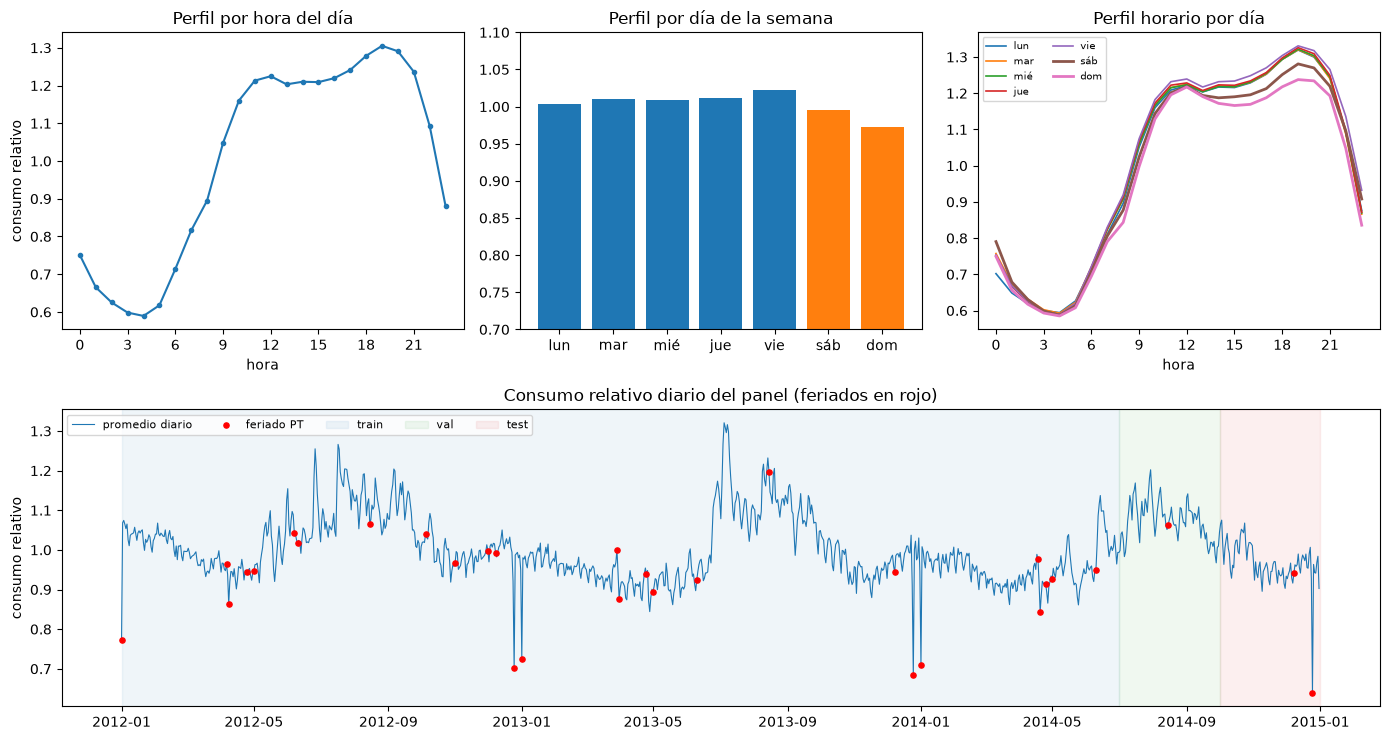

In [10]:
FERIADOS = holidays.Portugal(years=range(2011, 2016))
es_feriado = np.array([t.date() in FERIADOS for t in TIEMPOS])

rel = panel / panel.iloc[:T_VAL].mean()
rel_prom = rel.mean(axis=1)                         # perfil relativo promedio del panel
prof_hora = rel_prom.groupby(TIEMPOS.hour).mean()
dias_sem = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']
prof_sem = rel_prom.groupby(TIEMPOS.dayofweek).mean()
prof_hora_sem = rel_prom.groupby([TIEMPOS.dayofweek, TIEMPOS.hour]).mean().unstack(0)
diario = rel_prom.resample('D').mean()

fig = plt.figure(figsize=(14, 7.5))
ax1 = plt.subplot2grid((2, 3), (0, 0)); ax2 = plt.subplot2grid((2, 3), (0, 1)); ax3 = plt.subplot2grid((2, 3), (0, 2))
ax4 = plt.subplot2grid((2, 3), (1, 0), colspan=3)
ax1.plot(prof_hora.index, prof_hora.values, marker='o', ms=3)
ax1.set(title='Perfil por hora del día', xlabel='hora', ylabel='consumo relativo', xticks=range(0, 24, 3))
ax2.bar(dias_sem, prof_sem.values, color=['C0'] * 5 + ['C1'] * 2)
ax2.set(title='Perfil por día de la semana', ylim=(0.7, 1.1))
for j, d in enumerate(dias_sem):
    ax3.plot(prof_hora_sem.index, prof_hora_sem[j], label=d, lw=1.2 if j < 5 else 2)
ax3.set(title='Perfil horario por día', xlabel='hora', xticks=range(0, 24, 3)); ax3.legend(fontsize=7, ncol=2)
ax4.plot(diario.index, diario.values, lw=0.8, label='promedio diario')
fer_d = [pd.Timestamp(d) for d in FERIADOS if pd.Timestamp(INICIO) <= pd.Timestamp(d) <= pd.Timestamp(FIN)]
ax4.scatter(fer_d, diario.loc[fer_d].values, color='red', s=14, zorder=3, label='feriado PT')
for a, b, c, lab in [(INICIO, '2014-07-01', 'C0', 'train'), ('2014-07-01', '2014-10-01', 'C2', 'val'),
                     ('2014-10-01', FIN, 'C3', 'test')]:
    ax4.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=0.07, label=lab)
ax4.set(title='Consumo relativo diario del panel (feriados en rojo)', ylabel='consumo relativo'); ax4.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'perfiles_consumo.png'), dpi=130); plt.show()

**Navidad y Año Nuevo.** Se compara el consumo de cada día festivo contra el promedio del mismo día de la semana
en las 3 semanas previas (misma hora del año, sin efecto de estacionalidad semanal).

año      2012   2013   2014
día                        
24-dic  0.914  0.929  0.966
25-dic  0.689  0.693  0.665
31-dic  0.971  0.981  0.945
1-ene   0.796  0.797    NaN


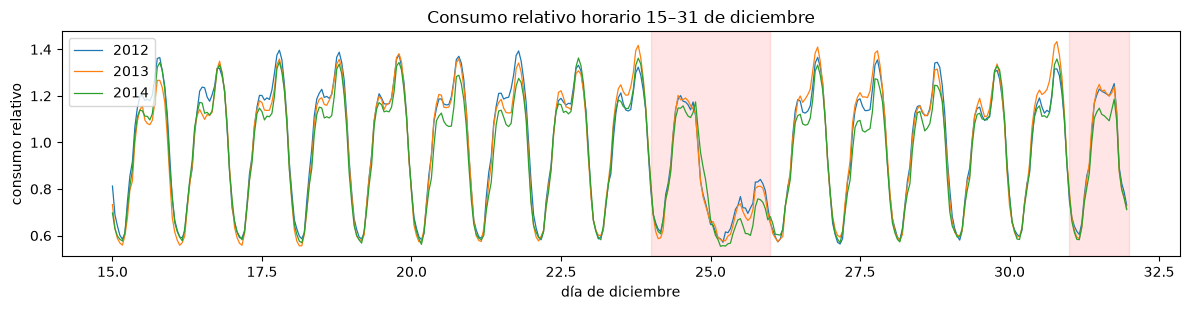

In [11]:
filas = []
for anio in (2012, 2013, 2014):
    for nombre, fecha in [('24-dic', f'{anio}-12-24'), ('25-dic', f'{anio}-12-25'),
                          ('31-dic', f'{anio}-12-31'), ('1-ene', f'{anio + 1}-01-01')]:
        f = pd.Timestamp(fecha)
        if f > pd.Timestamp(FIN):
            continue
        ref = diario.loc[[f - pd.Timedelta(weeks=k) for k in (1, 2, 3)]].mean()
        filas.append({'año': anio, 'día': nombre, 'día_sem': dias_sem[f.dayofweek],
                      'relativo_vs_3_semanas': round(diario.loc[f] / ref, 3)})
tabla_navidad = pd.DataFrame(filas).pivot(index='día', columns='año', values='relativo_vs_3_semanas')
print(tabla_navidad.loc[['24-dic', '25-dic', '31-dic', '1-ene']])

fig, ax = plt.subplots(figsize=(12, 3.2))
for anio in (2012, 2013, 2014):
    s = rel_prom.loc[f'{anio}-12-15':f'{anio}-12-31 23:00']
    ax.plot(np.arange(len(s)) / 24 + 15, s.values, lw=0.9, label=str(anio))
ax.axvspan(24, 26, color='red', alpha=0.1); ax.axvspan(31, 32, color='red', alpha=0.1)
ax.set(title='Consumo relativo horario 15–31 de diciembre', xlabel='día de diciembre', ylabel='consumo relativo')
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'navidad.png'), dpi=130); plt.show()

### 2.3 Escalas entre clientes y normalización

consumo promedio por cliente (kWh/h) en entrenamiento:
count      100.00
mean       529.44
std       1394.00
min         20.86
25%         84.15
50%        159.50
75%        318.33
max      11479.64

razón máximo / mínimo: 550×


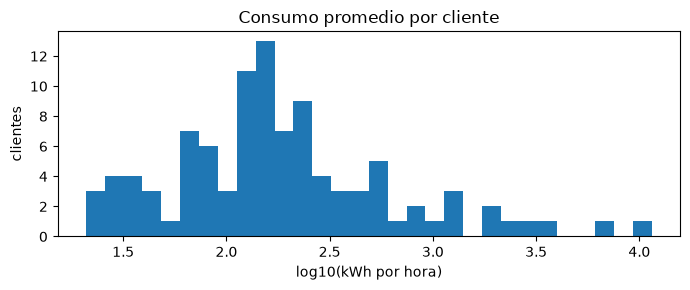

In [12]:
media_cli = panel.iloc[:T_VAL].mean()
print('consumo promedio por cliente (kWh/h) en entrenamiento:')
print(media_cli.describe(percentiles=[0.25, 0.5, 0.75]).round(2).to_string())
print(f'\nrazón máximo / mínimo: {media_cli.max() / media_cli.min():,.0f}×')
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(media_cli.values), bins=30)
ax.set(title='Consumo promedio por cliente', xlabel='log10(kWh por hora)', ylabel='clientes')
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'escalas_clientes.png'), dpi=130); plt.show()

Las escalas difieren en **varios órdenes de magnitud**. Opciones:

- **Global** (un solo μ, σ para todo el panel): la pérdida MSE quedaría dominada por los clientes grandes y los
  pequeños serían prácticamente constantes ≈ 0 para la red. Descartada.
- **Por serie** (z-score con μᵢ, σᵢ calculados **solo con entrenamiento**): pone a todos los clientes en la misma
  escala, permite un modelo **global** y no filtra información de validación/prueba. **Es la elegida por defecto.**
- **Por ventana** (RevIN: μ, σ de la ventana de entrada, que se revierten a la salida): se adapta a cambios de nivel
  recientes (p. ej. un cliente que cambia su consumo en 2014). Se implementa como opción (`norm='ventana'`) y se
  puede combinar con la anterior; es una de las iteraciones a explorar en 5.2.

In [13]:
MU = Y[:, :T_VAL].mean(axis=1, keepdims=True)           # (N, 1) — solo entrenamiento
SD = Y[:, :T_VAL].std(axis=1, keepdims=True) + 1e-6
Yn = ((Y - MU) / SD).astype(np.float32)                  # serie normalizada (N, T)

# Escala del MASE: MAE del seasonal naive de 24 h dentro de entrenamiento (por cliente).
M_MASE = 24
ESCALA_MASE = np.abs(Y[:, M_MASE:T_VAL] - Y[:, :T_VAL - M_MASE]).mean(axis=1)   # (N,)
print('Yn train: media', Yn[:, :T_VAL].mean().round(4), '| std', Yn[:, :T_VAL].std().round(4))

Yn train: media 0.0 | std 1.0


### 2.4 Covariables de calendario conocidas a futuro

Se conocen con certeza para cualquier instante futuro, así que pueden entrar al decoder / a la cabeza de salida.

| Covariable | Codificación | Motivo |
|---|---|---|
| hora (0–23) | seno/coseno, periodo 24 | las 23:00 quedan cerca de las 00:00 (continuidad cíclica) con solo 2 columnas |
| día de la semana (0–6) | seno/coseno, periodo 7 + indicador fin de semana | el sáb/dom es un régimen distinto, no solo una fase |
| mes (1–12) | seno/coseno, periodo 12 | estacionalidad anual suave |
| feriado | binaria (0/1) | días con comportamiento de domingo |

One-hot hubiera usado 24 + 7 + 12 columnas; con modelos globales y 100 series los embeddings serían otra opción,
pero seno/coseno es compacto, no requiere parámetros y funciona igual en todos los modelos.

In [14]:
def calendario(tiempos):
    h, d, m = tiempos.hour.values, tiempos.dayofweek.values, tiempos.month.values
    fer = np.array([t.date() in FERIADOS for t in tiempos], dtype=np.float32)
    return np.stack([np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
                     np.sin(2 * np.pi * d / 7),  np.cos(2 * np.pi * d / 7), (d >= 5).astype(float),
                     np.sin(2 * np.pi * (m - 1) / 12), np.cos(2 * np.pi * (m - 1) / 12), fer],
                    axis=1).astype(np.float32)

COLS_CAL = ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos', 'finde', 'mes_sin', 'mes_cos', 'feriado']
CAL = calendario(TIEMPOS)               # (T, C): depende solo de la marca de tiempo
C = CAL.shape[1]
print(pd.DataFrame(CAL[idx('2014-12-24 22:00'):idx('2014-12-25 03:00')], columns=COLS_CAL,
                   index=TIEMPOS[idx('2014-12-24 22:00'):idx('2014-12-25 03:00')]).round(3))

                     hora_sin  hora_cos  dow_sin  dow_cos  finde  mes_sin  mes_cos  feriado
2014-12-24 22:00:00    -0.500     0.866    0.975   -0.223    0.0     -0.5    0.866      0.0
2014-12-24 23:00:00    -0.259     0.966    0.975   -0.223    0.0     -0.5    0.866      0.0
2014-12-25 00:00:00     0.000     1.000    0.434   -0.901    0.0     -0.5    0.866      1.0
2014-12-25 01:00:00     0.259     0.966    0.434   -0.901    0.0     -0.5    0.866      1.0
2014-12-25 02:00:00     0.500     0.866    0.434   -0.901    0.0     -0.5    0.866      1.0


### 2.5 `Dataset` de ventanas deslizantes

Cada muestra es un par (cliente *i*, origen *t₀*):
- **X**: `(L, 1 + C)` = consumo normalizado `Yn[i, t₀−L : t₀]` + calendario `CAL[t₀−L : t₀]`.
- **y**: `(H,)` = `Yn[i, t₀ : t₀+H]`.
- **X_fut**: `(H, C)` = calendario `CAL[t₀ : t₀+H]` (conocido a futuro, para decoders y cabezas multi-salida).

Un origen es válido para una partición si **todo** su objetivo `[t₀, t₀+H)` cae dentro de ella. Con `diario=True`
solo se usan orígenes a las 00:00 (los del protocolo day-ahead). `__getitems__` arma el batch completo con
indexación vectorizada (mucho más rápido que 512 llamadas a `__getitem__`).

In [15]:
class VentanasDataset(Dataset):
    def __init__(self, Yn, CAL, L, H, t_ini, t_fin, stride=1, diario=False, series=None, t_min=0):
        self.Yn, self.CAL = torch.as_tensor(Yn), torch.as_tensor(CAL)
        self.L, self.H = L, H
        series = np.arange(Yn.shape[0]) if series is None else np.asarray(series)
        # orígenes: objetivo dentro de [t_ini, t_fin) y entrada que no empiece antes de t_min
        t0s = np.arange(max(t_ini, t_min + L), t_fin - H + 1, stride)
        if diario:
            t0s = t0s[t0s % 24 == 0]          # la malla empieza a las 00:00, así que t % 24 == 0 ⇔ 00:00
        self.series, self.t0s = series, t0s
        self.ar_L = torch.arange(-L, 0); self.ar_H = torch.arange(0, H)

    def __len__(self):
        return len(self.series) * len(self.t0s)

    def _decodifica(self, k):
        k = torch.as_tensor(k)
        return torch.as_tensor(self.series)[k // len(self.t0s)], torch.as_tensor(self.t0s)[k % len(self.t0s)]

    def __getitems__(self, ks):
        s, t0 = self._decodifica(np.asarray(ks))
        ti, to = t0[:, None] + self.ar_L, t0[:, None] + self.ar_H
        X = torch.cat([self.Yn[s[:, None], ti].unsqueeze(-1), self.CAL[ti]], dim=-1)   # (B, L, 1+C)
        return X, self.Yn[s[:, None], to], self.CAL[to], s                               # y: (B, H)

    def __getitem__(self, k):
        X, y, Xf, s = self.__getitems__([k])
        return X[0], y[0], Xf[0], s[0]

def loader(ds, batch=512, muestras=None, shuffle=False, seed=SEED):
    """DataLoader que entrega batches ya armados. `muestras` limita las ventanas por época (muestreo sin reemplazo)."""
    g = torch.Generator().manual_seed(seed)
    sampler = RandomSampler(ds, num_samples=muestras, generator=g) if (shuffle or muestras) else None
    return DataLoader(ds, batch_size=batch, sampler=sampler, collate_fn=lambda b: b)

L = 168
ds_tr = VentanasDataset(Yn, CAL, L, H, 0, T_VAL)
ds_va = VentanasDataset(Yn, CAL, L, H, T_VAL, T_TEST)
ds_te = VentanasDataset(Yn, CAL, L, H, T_TEST, T)
X, y, Xf, s = next(iter(loader(ds_tr, batch=4, shuffle=True)))
print('X', tuple(X.shape), '| y', tuple(y.shape), '| X_fut', tuple(Xf.shape), '| serie', s.tolist())

conteo = pd.DataFrame({
    'orígenes por serie (stride 1 h)': [len(d.t0s) for d in (ds_tr, ds_va, ds_te)],
    'ventanas en el panel (100 clientes)': [len(d) for d in (ds_tr, ds_va, ds_te)],
    f'ventanas con los {len(completos)} completos': [len(d.t0s) * len(completos) for d in (ds_tr, ds_va, ds_te)],
    'orígenes diarios 00:00 por serie': [len(VentanasDataset(Yn, CAL, L, H, a, b, diario=True).t0s)
                                         for a, b in ((0, T_VAL), (T_VAL, T_TEST), (T_TEST, T))],
}, index=['entrenamiento', 'validación', 'prueba'])
print(f'L = {L}, H = {H}, stride = 1 h'); print(conteo.to_string())

X (4, 168, 9) | y (4, 24) | X_fut (4, 24, 8) | serie [41, 77, 96, 11]
L = 168, H = 24, stride = 1 h
               orígenes por serie (stride 1 h)  ventanas en el panel (100 clientes)  ventanas con los 314 completos  orígenes diarios 00:00 por serie
entrenamiento                            21697                              2169700                         6812858                               905
validación                                2185                               218500                          686090                                92
prueba                                    2185                               218500                          686090                                92


Las primeras L = 168 horas de entrenamiento no pueden ser origen (no tienen historia suficiente) y las últimas
H − 1 = 23 horas de cada partición tampoco (su objetivo se saldría). En prueba hay **2,185** orígenes con stride de
1 h, de los cuales **92** son a las 00:00: esos 92 son los que usa el backtest.

### 2.6 Auditoría de fugas

Regla: **cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico** (00:00 del día
objetivo, con datos hasta las 23:00 del día anterior). Las cuatro fugas vistas en clase y cómo las evita el pipeline:

In [16]:
# Fuga 1 — split aleatorio de ventanas: las particiones se cortan por fecha, no se barajan ventanas entre ellas.
fin_obj_tr = ds_tr.t0s.max() + H - 1           # última hora objetivo de entrenamiento
ini_obj_va, fin_obj_va = ds_va.t0s.min(), ds_va.t0s.max() + H - 1
ini_obj_te = ds_te.t0s.min()
assert fin_obj_tr < T_VAL <= ini_obj_va and fin_obj_va < T_TEST <= ini_obj_te
print('1) objetivos train ≤', TIEMPOS[fin_obj_tr], '< val desde', TIEMPOS[ini_obj_va],
      '| val ≤', TIEMPOS[fin_obj_va], '< test desde', TIEMPOS[ini_obj_te])
print('   el barajado (shuffle) ocurre solo DENTRO de ds_tr (RandomSampler sobre ese Dataset)')

# Fuga 2 — escalar con toda la serie: μ y σ salen solo de [0, T_VAL).
mu_toda, sd_toda = Y.mean(axis=1), Y.std(axis=1)
assert np.allclose(MU[:, 0], Y[:, :T_VAL].mean(axis=1)) and not np.allclose(MU[:, 0], mu_toda)
print(f'2) μ con train vs. con toda la serie: diferencia media {np.abs(MU[:, 0] - mu_toda).mean() / MU.mean():.2%} '
      f'del nivel → se usan solo estadísticos de train (igual para la escala del MASE)')

# Fuga 3 — early stopping con la prueba: la función de entrenamiento solo recibe ds_tr y ds_va;
# ds_te no se pasa a `entrenar` y la prueba solo se toca en backtest() una vez por modelo (sección 4).
print('3) early stopping monitorea la pérdida de VALIDACIÓN (jul–sep 2014); prueba solo en backtest()')

# Fuga 4 — covariables mal alineadas: la última hora de X es t0−1 y las covariables futuras son las de [t0, t0+H).
X1, y1, Xf1, _ = ds_te[0]                       # muestra 0 = cliente 0, origen T_TEST
assert torch.allclose(X1[-1, 0], torch.tensor(Yn[0, T_TEST - 1]))      # último valor visto: 23:00 del día anterior
assert torch.allclose(y1[0], torch.tensor(Yn[0, T_TEST]))              # primer objetivo: 00:00
assert torch.allclose(Xf1, torch.tensor(CAL[T_TEST:T_TEST + H]))       # calendario del día objetivo
assert torch.allclose(X1[:, 1:], torch.tensor(CAL[T_TEST - L:T_TEST]))  # calendario de la entrada = sus propias horas
print('4) origen', TIEMPOS[T_TEST], '| última entrada', TIEMPOS[T_TEST - 1], '| objetivo',
      TIEMPOS[T_TEST], '→', TIEMPOS[T_TEST + H - 1])
print('   X_fut solo contiene calendario (función de la fecha), nunca consumo futuro;')
print('   no se usan rezagos < 1 ni promedios móviles centrados. Las correcciones DST usan solo el mismo día.')

1) objetivos train ≤ 2014-06-30 23:00:00 < val desde 2014-07-01 00:00:00 | val ≤ 2014-09-30 23:00:00 < test desde 2014-10-01 00:00:00
   el barajado (shuffle) ocurre solo DENTRO de ds_tr (RandomSampler sobre ese Dataset)
2) μ con train vs. con toda la serie: diferencia media 0.99% del nivel → se usan solo estadísticos de train (igual para la escala del MASE)
3) early stopping monitorea la pérdida de VALIDACIÓN (jul–sep 2014); prueba solo en backtest()
4) origen 2014-10-01 00:00:00 | última entrada 2014-09-30 23:00:00 | objetivo 2014-10-01 00:00:00 → 2014-10-01 23:00:00
   X_fut solo contiene calendario (función de la fecha), nunca consumo futuro;
   no se usan rezagos < 1 ni promedios móviles centrados. Las correcciones DST usan solo el mismo día.


## 3. Investigación: herramientas para forecasting en PyTorch

### 3.1 `nn.LSTM` y `nn.GRU` [1]

Redes recurrentes que recorren la secuencia paso a paso manteniendo un estado oculto. La LSTM tiene además una
**celda de memoria** `c` controlada por compuertas de entrada, olvido y salida; la GRU fusiona compuertas (reset y
update), no tiene celda y usa ~25 % menos parámetros.

| Parámetro | Propósito |
|---|---|
| `input_size` | número de features por paso (aquí 1 + 8 covariables = 9) |
| `hidden_size` | dimensión del estado oculto *h* (capacidad del modelo) |
| `num_layers` | capas recurrentes apiladas (la salida de una es la entrada de la siguiente) |
| `batch_first` | si `True`, tensores `(batch, seq, feature)` en vez de `(seq, batch, feature)` |
| `dropout` | dropout entre capas apiladas (no aplica a la última; requiere `num_layers > 1`) |

Salidas con `batch_first=True`: `output (B, L, D·hidden)` = estado oculto de la **última capa en cada paso**;
`h_n (D·num_layers, B, hidden)` = estado oculto **final de cada capa**; `c_n` (solo LSTM, misma forma que `h_n`) =
celda final de cada capa. `D = 2` si `bidirectional=True` (no se usa en forecasting causal). Para multi-salida se usa
`h_n[-1]` (o `output[:, -1]`, equivalente); para un encoder–decoder `(h_n, c_n)` inicializa el decoder.

### 3.2 `nn.Conv1d` con *dilation* y padding causal: TCN [2]

`nn.Conv1d(in_channels, out_channels, kernel_size, dilation, padding)` aplica filtros 1-D sobre el tiempo con entrada
`(B, canales, L)`. Con `dilation = d` el filtro toma muestras separadas `d` pasos. **Padding causal**: se rellenan
`(k−1)·d` ceros **solo a la izquierda** (`F.pad(x, ((k-1)*d, 0))` o padding simétrico y recortar la cola) para que la
salida en *t* dependa solo de *t, t−1, …* (nunca del futuro). Una TCN apila bloques residuales con
`d = 1, 2, 4, …, 2^(n−1)`; su **campo receptivo** es
`R = 1 + Σᵢ (k − 1)·dᵢ` (por cada convolución del bloque; con 2 convoluciones por bloque se multiplica por 2).
Ej.: k = 3 y d = 1…64 (7 niveles, 1 conv) → R = 1 + 2·127 = 255 h ≥ una semana.

### 3.3 `nn.TransformerEncoderLayer` y codificación posicional [1][3]

Bloque de **auto-atención multi-cabeza + red feed-forward**, cada una con residual y LayerNorm.
`d_model` = dimensión de los embeddings (debe ser divisible entre `nhead`); `nhead` = cabezas de atención, cada una de
dimensión `d_model / nhead`; `dim_feedforward` = ancho de la capa oculta del MLP (típicamente 2–4 × `d_model`);
además `dropout`, `batch_first`, `norm_first`. Se apila con `nn.TransformerEncoder(layer, num_layers)`.
La atención es invariante a permutaciones, así que el orden se inyecta **sumando** una codificación posicional al
embedding de entrada: sinusoidal fija `PE(t, 2i) = sin(t / 10000^{2i/d})`, `PE(t, 2i+1) = cos(·)` o una
`nn.Parameter` aprendida `(L, d_model)`. En series de tiempo también se suman las covariables de calendario
proyectadas, y PatchTST [4] agrupa la serie en *patches* (p. ej. 16 h) que actúan como tokens.

### 3.4 NeuralForecast y StatsForecast (Nixtla) [5][6]

Ambas reciben un **DataFrame largo** con columnas `unique_id` (id de la serie), `ds` (marca de tiempo) e `y`
(valor); las covariables futuras van como columnas extra y se declaran con `futr_exog_list`. Se instancian con una
lista de modelos y la frecuencia: `StatsForecast(models=[...], freq='h', n_jobs=-1)` /
`NeuralForecast(models=[NHITS(h=24, input_size=168, ...)], freq='h')`.

`cross_validation(df, h, n_windows, step_size, refit)` hace backtesting con origen móvil:
- `n_windows`: número de orígenes (aquí 92);
- `step_size`: separación entre orígenes consecutivos (24 h → un pronóstico por día);
- `refit`: `False` entrena una sola vez en el primer corte y luego solo predice con la historia nueva (protocolo de
  este lab); `True` reentrena en cada ventana; un entero *k* reentrena cada *k* ventanas (útil para el reentrenamiento
  mensual). En NeuralForecast además están `val_size`/`test_size`.
Devuelve `unique_id, ds, cutoff, y` y una columna por modelo, listo para calcular métricas.

### 3.5 `BaseChronosPipeline.predict_quantiles` (Chronos) [7]

Chronos es un modelo fundacional preentrenado (Chronos-Bolt: encoder–decoder T5 que predice cuantiles directamente).
`BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small')` carga el modelo y
`predict_quantiles(context, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])` recibe `context` como tensor
1-D o `(batch, longitud)` (o lista de tensores de distinto largo) con la **historia cruda** (escala interna propia) y
devuelve `(quantiles (B, H, Q), mean (B, H))`. Es **zero-shot**: no se entrena.

### 3.6 Conceptos

- **Modelo local vs. global.** Local = un modelo por serie (ARIMA/ETS clásicos): se adapta a cada cliente pero cada uno
  aprende de ~22 k puntos y no transfiere patrones. Global = un solo modelo para todas las series (normalizadas): ve
  100× más datos, comparte patrones (hora, día, feriados) y generaliza a series nuevas; es lo que hace funcionar al
  deep learning en forecasting [8].
- **Teacher forcing.** Al entrenar un modelo autorregresivo / seq2seq, en cada paso del decoder se alimenta el
  **valor real** anterior en lugar de la predicción. Acelera y estabiliza el entrenamiento, pero en inferencia el
  modelo ve sus propios errores (*exposure bias*); se mitiga con *scheduled sampling* (alimentar la predicción con
  probabilidad creciente).
- **RevIN** [9]. Normaliza cada ventana de entrada con su propia media y desviación (más un afín aprendible), pasa la
  ventana normalizada a la red y **revierte** la transformación en la salida. Ante un cambio de nivel (el cliente
  consume 30 % más en 2014 que en 2012) la red ve siempre una ventana centrada, así que no extrapola fuera del rango
  de entrenamiento.
- **Pinball loss.** Para un cuantil τ: `ρ_τ(y, ŷ) = max(τ·(y − ŷ), (τ − 1)·(y − ŷ))`. Penaliza la sub-predicción con
  peso τ y la sobre-predicción con 1 − τ; su minimizador es el **cuantil τ** de la distribución condicional
  (τ = 0.5 → mediana, equivale a MAE/2). Promediada sobre varios τ aproxima el CRPS.
- **MASE vs. WAPE.** MASE = MAE del modelo / MAE del seasonal naive *dentro de entrenamiento*: < 1 significa mejor que
  repetir el día anterior y se promedia por serie (cada cliente pesa igual). WAPE = Σ|error| / Σ|real| sobre todo el
  panel: es un % del volumen total, por lo que pesa más a los clientes grandes. Ambos son libres de escala, pero
  ninguno explota con valores reales ≈ 0 (a diferencia del MAPE).

**Referencias**
[1] PyTorch docs — `torch.nn` (LSTM, GRU, Conv1d, TransformerEncoderLayer). ·
[2] Bai, Kolter & Koltun (2018), *An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling*. ·
[3] Vaswani et al. (2017), *Attention Is All You Need*. ·
[4] Nie et al. (2023), *A Time Series is Worth 64 Words* (PatchTST). ·
[5] Nixtla, *StatsForecast* docs. · [6] Nixtla, *NeuralForecast* docs. ·
[7] Ansari et al. (2024), *Chronos: Learning the Language of Time Series*; repo `amazon-science/chronos-forecasting`. ·
[8] Montero-Manso & Hyndman (2021), *Principles and algorithms for forecasting groups of time series: locality and globality*. ·
[9] Kim et al. (2022), *Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift*. ·
[10] Zeng et al. (2023), *Are Transformers Effective for Time Series Forecasting?* (DLinear/NLinear).

## 4. Protocolo de validación y métricas

Una sola función `backtest(modelo)` evalúa **todos** los modelos. El modelo solo tiene que exponer
`predecir(hist, t0) → (N, 24)` en kWh, donde `hist = Y[:, :t0]` es una **copia de solo lectura** con los datos hasta
las 23:00 del día anterior: el modelo físicamente no puede ver el futuro. Si además devuelve cuantiles
`(N, 24, 3)` para P10/P50/P90, se guardan para las métricas probabilísticas.

Para modelos de librería (StatsForecast, NeuralForecast, LightGBM, Chronos) cuyo `cross_validation` ya produce los
92 pronósticos, `PronosticosPrecalculados` los adapta a la misma interfaz y `backtest` verifica que el `cutoff` de
cada pronóstico sea exactamente el origen (23:00 del día anterior).

In [17]:
N_ORIGENES = (T - T_TEST) // 24          # 92
ORIGENES = T_TEST + 24 * np.arange(N_ORIGENES)
Y_RO = Y.copy(); Y_RO.flags.writeable = False
assert N_ORIGENES == 92

def backtest(modelo, origenes=ORIGENES, H=H):
    """Backtesting con origen móvil diario. Devuelve un DataFrame largo con y, y_hat (y cuantiles si existen)."""
    preds, cuant = [], []
    t_ini = time.perf_counter()
    for t0 in origenes:
        out = modelo.predecir(Y_RO[:, :t0], int(t0))
        if isinstance(out, tuple):
            out, q = out; cuant.append(np.asarray(q))
        out = np.asarray(out, dtype=np.float64)
        assert out.shape == (N, H), f'{modelo.nombre}: forma {out.shape}'
        preds.append(out)
    t_inf = time.perf_counter() - t_ini
    P = np.stack(preds, axis=1)                                   # (N, O, H)
    tt = np.asarray(origenes)[:, None] + np.arange(H)             # (O, H) índices de tiempo
    res = pd.DataFrame({
        'unique_id': np.repeat(CLIENTES, len(origenes) * H),
        'ds': np.tile(TIEMPOS[tt.ravel()], N),
        'origen': np.tile(np.repeat(TIEMPOS[np.asarray(origenes) - 1], H), N),   # cutoff = 23:00 del día anterior
        'h': np.tile(np.arange(1, H + 1), N * len(origenes)),
        'y': Y[:, tt].ravel(),
        'y_hat': P.ravel()})
    if cuant:
        Q = np.stack(cuant, axis=1)                               # (N, O, H, 3)
        for j, nom in enumerate(['p10', 'p50', 'p90']):
            res[nom] = Q[..., j].ravel()
    res['modelo'] = modelo.nombre
    res.attrs['t_inferencia_s'] = t_inf
    return res

class PronosticosPrecalculados:
    """Adapta la salida de `cross_validation` (unique_id, ds, cutoff, <col>) a la interfaz de backtest."""
    def __init__(self, df, col, nombre=None, cuantiles=None):
        self.nombre = nombre or col
        df = df.copy(); df['ds'] = pd.to_datetime(df['ds']); df['cutoff'] = pd.to_datetime(df['cutoff'])
        cols = [col] + (list(cuantiles) if cuantiles else [])
        self.tab = df.pivot_table(index=['cutoff', 'ds'], columns='unique_id', values=cols)
        self.col, self.cuantiles = col, cuantiles

    def predecir(self, hist, t0):
        corte = TIEMPOS[t0 - 1]
        assert hist.shape[1] == t0
        bloque = self.tab.loc[corte]                               # falla si no existe un pronóstico con ese cutoff
        assert (bloque.index == TIEMPOS[t0:t0 + H]).all(), 'pronóstico desalineado con el origen'
        yhat = bloque[self.col][CLIENTES].values.T                 # (N, H)
        if self.cuantiles:
            q = np.stack([bloque[c][CLIENTES].values.T for c in self.cuantiles], axis=-1)
            return yhat, q
        return yhat

**Métricas** (en kWh, agregadas sobre todos los clientes y orígenes):

- **MAE**, **RMSE**; también por cliente.
- **WAPE** = Σ|error| / Σ|real| sobre todo el panel.
- **MAPE** = promedio de |error| / |real| (sobre horas con real > 0). Con clientes de consumo ≈ 0 el denominador
  minúsculo hace que un error de pocos kWh valga cientos de %, así que el MAPE lo dominan esos clientes.
- **MASE** = MAEᵢ / escalaᵢ por cliente, con escalaᵢ = MAE del seasonal naive de 24 h en entrenamiento; se promedia
  sobre clientes.
- Probabilísticas: **pinball loss** promedio en P10/P50/P90 (normalizada por la escala MASE para ser comparable) y
  **cobertura** P10–P90 (ideal: 80 %).

In [18]:
ESCALA = pd.Series(ESCALA_MASE, index=CLIENTES)
NAVIDAD = ('2014-12-22 00:00', '2014-12-28 23:00')

def _mase(df):
    mae_i = (df['y'] - df['y_hat']).abs().groupby(df['unique_id']).mean()
    return float((mae_i / ESCALA.loc[mae_i.index]).mean())

def metricas(res):
    e = res['y_hat'] - res['y']
    pos = res['y'] > 0
    m = {'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()),
         'WAPE': e.abs().sum() / res['y'].abs().sum(),
         'MAPE': (e[pos].abs() / res['y'][pos]).mean(),
         'MASE': _mase(res)}
    nav = res[(res['ds'] >= NAVIDAD[0]) & (res['ds'] <= NAVIDAD[1])]
    m['MASE_navidad'] = _mase(nav)
    if 'p10' in res:
        tau = {'p10': 0.1, 'p50': 0.5, 'p90': 0.9}
        pin = np.mean([np.maximum(t * (res['y'] - res[c]), (t - 1) * (res['y'] - res[c])) /
                       ESCALA.loc[res['unique_id']].values for c, t in tau.items()], axis=0)
        m['pinball_esc'] = float(pin.mean())
        m['cobertura_80'] = float(((res['y'] >= res['p10']) & (res['y'] <= res['p90'])).mean())
    return m

def metricas_por_cliente(res):
    g = res.assign(ae=(res['y_hat'] - res['y']).abs(), se=(res['y_hat'] - res['y']) ** 2).groupby('unique_id')
    out = pd.DataFrame({'MAE': g['ae'].mean(), 'RMSE': np.sqrt(g['se'].mean()), 'media_y': g['y'].mean()})
    out['MASE'] = out['MAE'] / ESCALA.loc[out.index]
    return out

def error_por_paso(res):
    return (res['y_hat'] - res['y']).abs().groupby(res['h']).mean()          # MAE por h = 1…24

def error_por_hora(res):
    return (res['y_hat'] - res['y']).abs().groupby(res['ds'].dt.hour).mean()  # MAE por hora del día

RESULTADOS, METRICAS, INFO = {}, {}, {}    # resultados de backtest, métricas y metadatos por modelo

def registrar(res, **info):
    """Guarda el backtest de un modelo y sus métricas (la prueba se usa una sola vez por modelo)."""
    nom = res['modelo'].iat[0]
    RESULTADOS[nom] = res
    METRICAS[nom] = metricas(res)
    INFO[nom] = dict(info, t_inferencia_s=res.attrs.get('t_inferencia_s', np.nan))
    print(f"{nom:<22} MAE {METRICAS[nom]['MAE']:8.3f}  RMSE {METRICAS[nom]['RMSE']:8.3f}  "
          f"WAPE {METRICAS[nom]['WAPE']:.4f}  MAPE {METRICAS[nom]['MAPE']:.3f}  MASE {METRICAS[nom]['MASE']:.4f}  "
          f"MASE nav. {METRICAS[nom]['MASE_navidad']:.4f}")

## 5. Construcción y entrenamiento de los modelos

### 5.0 Baselines (StatsForecast)

Naive (repite la última hora), seasonal naive de 24 h (repite el día anterior) y de 168 h (repite el mismo día de la
semana pasada), y **MSTL** (descomposición con estacionalidades de 24 y 168 h + AutoETS sobre la tendencia).
Naive y seasonal naive usan `cross_validation(h=24, step_size=24, n_windows=92, refit=False)`: no tienen pesos, en cada
origen solo leen la historia hasta las 23:00 del día anterior. MSTL es un modelo **local** (una descomposición por
cliente): se reajusta en cada origen con las últimas 4 semanas (`input_size=672`, `refit=True`), que es su forma
natural de operar y sigue usando solo datos anteriores al origen. Cuesta ~0.07 s por ajuste × 9,200 ajustes,
así que se paraleliza con `n_jobs=-1`.

In [19]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS

DF_LARGO = (panel.rename_axis('ds').reset_index()
            .melt(id_vars='ds', var_name='unique_id', value_name='y')[['unique_id', 'ds', 'y']])
CV_CACHE = os.path.join(DATA, 'cv_statsforecast.parquet')
if os.path.exists(CV_CACHE) and not RETRAIN:
    cv_sf = pd.read_parquet(CV_CACHE); t_sf = json.load(open(CV_CACHE + '.json'))
else:
    t_sf = {}
    modelos_sf = [Naive(), SeasonalNaive(24, alias='SeasonalNaive24'), SeasonalNaive(168, alias='SeasonalNaive168')]
    sf = StatsForecast(models=modelos_sf, freq='h', n_jobs=-1)
    t = time.perf_counter()
    cv_sf = sf.cross_validation(df=DF_LARGO, h=H, step_size=24, n_windows=N_ORIGENES, refit=False)
    t_sf['simples'] = time.perf_counter() - t
    # MSTL: se reajusta en cada origen con las últimas 4 semanas (input_size) para que el ajuste sea barato.
    sf_mstl = StatsForecast(models=[MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model='ZZN'),
                                         alias='MSTL')], freq='h', n_jobs=-1)
    t = time.perf_counter()
    cv_m = sf_mstl.cross_validation(df=DF_LARGO, h=H, step_size=24, n_windows=N_ORIGENES, refit=True,
                                    input_size=24 * 7 * 4)
    t_sf['MSTL'] = time.perf_counter() - t
    cv_sf = cv_sf.merge(cv_m[['unique_id', 'ds', 'cutoff', 'MSTL']], on=['unique_id', 'ds', 'cutoff'])
    cv_sf.to_parquet(CV_CACHE); json.dump(t_sf, open(CV_CACHE + '.json', 'w'))
print('tiempos StatsForecast (s):', {k: round(v, 1) for k, v in t_sf.items()})

for col, L_eq in [('Naive', 1), ('SeasonalNaive24', 24), ('SeasonalNaive168', 168), ('MSTL', 24 * 7 * 4)]:
    res = backtest(PronosticosPrecalculados(cv_sf, col))
    t_fit = t_sf['MSTL'] if col == 'MSTL' else t_sf['simples'] / 3
    registrar(res, familia='Baseline', L=L_eq, estrategia='—', covariables=False, params=0, params_entrenables=0,
              t_entrenamiento_s=t_fit, hardware='CPU (StatsForecast)')

tiempos StatsForecast (s): {'simples': 2.1, 'MSTL': 88.4}
Naive                  MAE  158.588  RMSE  504.684  WAPE 0.3077  MAPE 0.400  MASE 3.9891  MASE nav. 3.9055
SeasonalNaive24        MAE   44.128  RMSE  232.232  WAPE 0.0856  MAPE 0.118  MASE 1.0341  MASE nav. 2.1679


SeasonalNaive168       MAE   39.721  RMSE  182.448  WAPE 0.0771  MAPE 0.112  MASE 1.1137  MASE nav. 1.6018
MSTL                   MAE   36.034  RMSE  182.711  WAPE 0.0699  MAPE 0.104  MASE 0.9373  MASE nav. 1.9695


### 5.1 Modelos propios en PyTorch

Todos son **globales** (un modelo para los 100 clientes), trabajan sobre la serie normalizada por cliente y
comparten la firma `forward(X, X_fut) → (B, 24)`:

| Modelo | Entrada | Estrategia multi-paso | Covariables |
|---|---|---|---|
| **MLP** | últimas L horas + calendario futuro aplanado | multi-salida | sí (futuras) |
| **DLinear** [10] | últimas L horas, descompuestas en tendencia (media móvil k = 25) + estacional, una capa lineal L→H por componente | multi-salida | no |
| **NLinear** [10] | últimas L horas menos el último valor; lineal L→H; se suma el último valor | multi-salida | no |
| **LSTM multi-salida** | X `(L, 9)` → LSTM → `h_n` + calendario futuro → lineal → 24 | multi-salida | sí |
| **LSTM autorregresiva** | un paso: `[y_t, cal_{t+1}] → ŷ_{t+1}`; se realimenta 24 veces | recursiva | sí |
| **Seq2seq (LSTM)** | encoder LSTM sobre X; decoder LSTM con `[ŷ_{t−1}, cal_t]` inicializado con `(h_n, c_n)` | encoder–decoder | sí (en el decoder) |

`ConRevIN` envuelve cualquiera de ellos para la normalización **por ventana** (opción `norm='ventana'`).

In [20]:
class MLP(nn.Module):
    def __init__(self, L, H=24, C=8, oculto=512, dropout=0.1):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(L + H * C, oculto), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(oculto, oculto // 2), nn.ReLU(), nn.Linear(oculto // 2, H))
    def forward(self, X, Xf):
        return self.red(torch.cat([X[:, :, 0], Xf.flatten(1)], dim=1))

class DLinear(nn.Module):
    def __init__(self, L, H=24, k=25):
        super().__init__()
        self.k = k
        self.lin_est, self.lin_ten = nn.Linear(L, H), nn.Linear(L, H)
    def forward(self, X, Xf=None):
        x = X[:, :, 0]
        # media móvil con relleno replicado en ambos extremos de la VENTANA (no usa datos fuera de ella)
        xp = torch.cat([x[:, :1].repeat(1, (self.k - 1) // 2), x, x[:, -1:].repeat(1, self.k // 2)], dim=1)
        tendencia = F.avg_pool1d(xp.unsqueeze(1), self.k, stride=1).squeeze(1)
        return self.lin_est(x - tendencia) + self.lin_ten(tendencia)

class NLinear(nn.Module):
    def __init__(self, L, H=24):
        super().__init__()
        self.lin = nn.Linear(L, H)
    def forward(self, X, Xf=None):
        x = X[:, :, 0]; ultimo = x[:, -1:]
        return self.lin(x - ultimo) + ultimo

class LSTMMultiSalida(nn.Module):
    def __init__(self, C=8, H=24, oculto=64, capas=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=dropout if capas > 1 else 0)
        self.cabeza = nn.Linear(oculto + H * C, H)
    def forward(self, X, Xf):
        _, (h_n, _) = self.lstm(X)
        return self.cabeza(torch.cat([h_n[-1], Xf.flatten(1)], dim=1))

class LSTMAutorregresiva(nn.Module):
    """Modelo de un paso. Entrena con teacher forcing sobre la secuencia [t0−L, t0+H); predice recursivamente."""
    def __init__(self, C=8, oculto=64, capas=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=dropout if capas > 1 else 0)
        self.salida = nn.Linear(oculto, 1)
    def perdida(self, X, y, Xf, fn):
        yfull = torch.cat([X[:, :, 0], y], dim=1)                 # (B, L+H): valores reales (teacher forcing)
        calfull = torch.cat([X[:, :, 1:], Xf], dim=1)             # (B, L+H, C)
        z = torch.cat([yfull[:, :-1, None], calfull[:, 1:]], dim=-1)   # entrada en t: [y_t, cal_{t+1}]
        out, _ = self.lstm(z)
        return fn(self.salida(out).squeeze(-1), yfull[:, 1:])      # objetivo: y_{t+1} (un paso)
    def forward(self, X, Xf):
        calfull = torch.cat([X[:, :, 1:], Xf], dim=1)
        z = torch.cat([X[:, :, :1], calfull[:, 1:X.shape[1] + 1]], dim=-1)
        out, estado = self.lstm(z)
        y_t = self.salida(out[:, -1])                              # ŷ_{t0}
        preds = [y_t]
        for h in range(1, Xf.shape[1]):                            # realimenta su propia predicción
            out, estado = self.lstm(torch.cat([y_t, Xf[:, h]], dim=-1).unsqueeze(1), estado)
            y_t = self.salida(out[:, -1]); preds.append(y_t)
        return torch.cat(preds, dim=1)

class Seq2Seq(nn.Module):
    """Encoder LSTM + decoder LSTM con covariables de calendario del día objetivo."""
    def __init__(self, C=8, oculto=64, capas=2, dropout=0.1, p_teacher=0.5):
        super().__init__()
        d = dropout if capas > 1 else 0
        self.enc = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=d)
        self.dec = nn.LSTM(1 + C, oculto, capas, batch_first=True, dropout=d)
        self.salida = nn.Linear(oculto, 1)
        self.p_teacher = p_teacher
    def _decodifica(self, X, Xf, y=None):
        _, estado = self.enc(X)
        y_prev = X[:, -1, :1]                                      # último valor observado (23:00)
        preds = []
        for h in range(Xf.shape[1]):
            out, estado = self.dec(torch.cat([y_prev, Xf[:, h]], dim=-1).unsqueeze(1), estado)
            y_h = self.salida(out[:, -1]); preds.append(y_h)
            usar_real = y is not None and torch.rand(()) < self.p_teacher
            y_prev = y[:, h:h + 1] if usar_real else y_h           # teacher forcing con probabilidad p_teacher
        return torch.cat(preds, dim=1)
    def perdida(self, X, y, Xf, fn):
        return fn(self._decodifica(X, Xf, y), y)
    def forward(self, X, Xf):
        return self._decodifica(X, Xf)

class ConRevIN(nn.Module):
    """Normalización por ventana (RevIN): normaliza el canal de consumo con μ, σ de la entrada y revierte a la salida."""
    def __init__(self, base, eps=1e-5):
        super().__init__()
        self.base, self.eps = base, eps
        self.gamma, self.beta = nn.Parameter(torch.ones(1)), nn.Parameter(torch.zeros(1))
    def _norm(self, X):
        m = X[:, :, :1].mean(1, keepdim=True); s = X[:, :, :1].std(1, keepdim=True) + self.eps
        Xn = torch.cat([(X[:, :, :1] - m) / s * self.gamma + self.beta, X[:, :, 1:]], dim=-1)
        return Xn, m[:, :, 0], s[:, :, 0]
    def _desnorm(self, o, m, s):
        return (o - self.beta) / self.gamma * s + m
    def forward(self, X, Xf):
        Xn, m, s = self._norm(X)
        return self._desnorm(self.base(Xn, Xf), m, s)
    def perdida(self, X, y, Xf, fn):
        if hasattr(self.base, 'perdida'):          # entrena en la escala de la ventana
            Xn, m, s = self._norm(X)
            return self.base.perdida(Xn, (y - m) / s * self.gamma + self.beta, Xf, fn)
        return fn(self.forward(X, Xf), y)

### 5.2 Entrenamiento con registro de iteraciones

`entrenar(nombre, construir, cfg)` entrena **solo con `ds_tr` y `ds_va`** y registra todo lo que pide el enunciado:
configuración (L, H, meses de historia, normalización, tamaño oculto, capas, dropout, lr, batch), pérdida de
entrenamiento y validación por época, **MAE y MASE de validación al final de cada época** (en kWh, sobre los 92
orígenes diarios de jul–sep), parámetros totales/entrenables, tiempo por época y total, y memoria pico de GPU.
Cada época usa una muestra aleatoria de `muestras` ventanas de entrenamiento (de ~2.2 M posibles con stride 1 h).
**Early stopping** con paciencia sobre la pérdida de validación; se restauran los mejores pesos.
Los pesos y el historial se guardan en `data/modelos/` y se reutilizan al re-ejecutar.

In [21]:
CFG_BASE = dict(L=168, H=24, meses=None, norm='serie', lr=1e-3, batch=512, muestras=100_000,
                epocas=40, paciencia=5, perdida='mae', weight_decay=0.0, seed=SEED)
if QUICK:
    CFG_BASE.update(muestras=4_000, epocas=2)
ITERACIONES = []        # una fila por entrenamiento (para la tabla de iteraciones de 5.2)
HISTORIALES = {}        # curvas por época

def _sync():
    if DEVICE.type == 'mps': torch.mps.synchronize()
    elif DEVICE.type == 'cuda': torch.cuda.synchronize()

def _mem_gpu():
    if DEVICE.type == 'mps': return torch.mps.driver_allocated_memory() / 2**20
    if DEVICE.type == 'cuda': return torch.cuda.max_memory_allocated() / 2**20
    return float('nan')

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

def ds_entrenamiento(cfg):
    """Ventanas de entrenamiento; con `meses` solo se usa la historia más reciente antes de 2014-07-01."""
    t_min = 0 if cfg['meses'] is None else max(0, idx(TIEMPOS[T_VAL] - pd.DateOffset(months=cfg['meses'])))
    return VentanasDataset(Yn, CAL, cfg['L'], cfg['H'], 0, T_VAL, t_min=t_min)

@torch.no_grad()
def evaluar_val(modelo, ds_va, fn):
    """Pérdida (escala normalizada) y MAE / MASE en kWh sobre los orígenes diarios de validación."""
    modelo.eval(); perd, ae, sid = [], [], []
    for X, y, Xf, s in loader(ds_va, batch=2048):
        X, y, Xf = X.to(DEVICE), y.to(DEVICE), Xf.to(DEVICE)
        p = modelo(X, Xf)
        perd.append(fn(p, y, reduction='none').mean(1).cpu())
        sd = torch.as_tensor(SD[s.numpy(), 0], dtype=torch.float32)[:, None]
        ae.append(((p.cpu() - y.cpu()).abs() * sd).mean(1)); sid.append(s)
    ae, sid = torch.cat(ae).numpy(), torch.cat(sid).numpy()
    mae_i = pd.Series(ae).groupby(sid).mean()
    return float(torch.cat(perd).mean()), float(ae.mean()), float((mae_i / ESCALA_MASE[mae_i.index]).mean())

def entrenar(nombre, construir, cfg=None, **cambios):
    cfg = dict(CFG_BASE, **(cfg or {}), **cambios)
    fijar_semillas(cfg['seed'])
    modelo = construir(cfg)
    if cfg['norm'] == 'ventana':
        modelo = ConRevIN(modelo)
    modelo = modelo.to(DEVICE)
    fn = F.l1_loss if cfg['perdida'] == 'mae' else F.mse_loss
    ruta = os.path.join(MODELOS, f'{nombre}.pt')
    total, entrenables = contar_parametros(modelo)
    if os.path.exists(ruta) and not RETRAIN and not QUICK:
        ck = torch.load(ruta, map_location=DEVICE, weights_only=False)
        modelo.load_state_dict(ck['pesos']); hist, resumen = ck['hist'], ck['resumen']
        print(f'{nombre}: pesos cargados de caché ({resumen["epocas"]} épocas, MASE val {resumen["MASE_val"]:.4f})')
    else:
        ds_tr_c, ds_va_c = ds_entrenamiento(cfg), VentanasDataset(Yn, CAL, cfg['L'], cfg['H'], T_VAL, T_TEST, diario=True)
        opt = torch.optim.AdamW(modelo.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
        if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()
        hist, mejor, sin_mejora, mem_pico = [], (float('inf'), None), 0, 0.0
        t_total = time.perf_counter()
        for ep in range(1, cfg['epocas'] + 1):
            modelo.train(); t_ep = time.perf_counter(); acum, nb = 0.0, 0
            muestras = min(cfg['muestras'], len(ds_tr_c))
            for X, y, Xf, _ in loader(ds_tr_c, batch=cfg['batch'], muestras=muestras, seed=cfg['seed'] + ep):
                X, y, Xf = X.to(DEVICE), y.to(DEVICE), Xf.to(DEVICE)
                loss = modelo.perdida(X, y, Xf, fn) if hasattr(modelo, 'perdida') else fn(modelo(X, Xf), y)
                opt.zero_grad(set_to_none=True); loss.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0); opt.step()
                acum += loss.item(); nb += 1
            _sync(); t_ep = time.perf_counter() - t_ep
            mem_pico = max(mem_pico, _mem_gpu())
            l_va, mae_va, mase_va = evaluar_val(modelo, ds_va_c, fn)
            hist.append(dict(epoca=ep, loss_train=acum / nb, loss_val=l_va, MAE_val=mae_va, MASE_val=mase_va, t_epoca_s=t_ep))
            if l_va < mejor[0] - 1e-5:
                mejor = (l_va, {k: v.detach().clone() for k, v in modelo.state_dict().items()}); sin_mejora = 0
            else:
                sin_mejora += 1
            print(f'  {nombre} ep {ep:2d} | train {acum / nb:.4f} | val {l_va:.4f} | MAE val {mae_va:8.2f} kWh '
                  f'| MASE val {mase_va:.4f} | {t_ep:5.1f} s')
            if sin_mejora >= cfg['paciencia']:
                break
        modelo.load_state_dict(mejor[1])
        mejor_ep = min(hist, key=lambda r: r['loss_val'])
        resumen = dict(epocas=len(hist), mejor_epoca=mejor_ep['epoca'], MAE_val=mejor_ep['MAE_val'],
                       MASE_val=mejor_ep['MASE_val'], t_total_s=time.perf_counter() - t_total,
                       t_epoca_s=float(np.mean([r['t_epoca_s'] for r in hist])), mem_pico_MB=mem_pico)
        if not QUICK:
            torch.save({'pesos': modelo.state_dict(), 'hist': hist, 'resumen': resumen, 'cfg': cfg}, ruta)
    HISTORIALES[nombre] = pd.DataFrame(hist)
    fila = dict(modelo=nombre, **{k: cfg[k] for k in ('L', 'H', 'meses', 'norm', 'lr', 'batch', 'muestras', 'seed')},
                **{k: cfg[k] for k in cfg if k not in CFG_BASE}, params=total, params_entrenables=entrenables, **resumen)
    ITERACIONES[:] = [r for r in ITERACIONES if r['modelo'] != nombre] + [fila]
    modelo.eval()
    return modelo, cfg, fila

class PronosticadorTorch:
    """Adapta un modelo entrenado a la interfaz de backtest: normaliza con μ, σ de train y usa solo hist[:, t0−L:t0]."""
    def __init__(self, nombre, modelo, cfg):
        self.nombre, self.modelo, self.L = nombre, modelo, cfg['L']
        self.mu, self.sd = torch.as_tensor(MU, dtype=torch.float32), torch.as_tensor(SD, dtype=torch.float32)
    @torch.no_grad()
    def predecir(self, hist, t0):
        x = (torch.as_tensor(hist[:, t0 - self.L:t0], dtype=torch.float32) - self.mu) / self.sd
        cal = torch.as_tensor(CAL[t0 - self.L:t0]).expand(N, -1, -1)
        X = torch.cat([x.unsqueeze(-1), cal], dim=-1).to(DEVICE)
        Xf = torch.as_tensor(CAL[t0:t0 + H]).expand(N, -1, -1).to(DEVICE)
        return (self.modelo(X, Xf).cpu() * self.sd + self.mu).numpy()

def entrenar_y_evaluar(nombre, construir, familia, estrategia, covariables, **cambios):
    modelo, cfg, fila = entrenar(nombre, construir, **cambios)
    res = backtest(PronosticadorTorch(nombre, modelo, cfg))
    registrar(res, familia=familia, L=cfg['L'], estrategia=estrategia, covariables=covariables,
              params=fila['params'], params_entrenables=fila['params_entrenables'],
              t_entrenamiento_s=fila['t_total_s'], hardware=HARDWARE)
    return modelo, cfg, res

### 5.3 MLP, DLinear y NLinear (L = 168)

In [22]:
mlp, cfg_mlp, _ = entrenar_y_evaluar(
    'MLP', lambda c: MLP(c['L'], c['H'], C, oculto=c.get('oculto', 512), dropout=c.get('dropout', 0.1)),
    'MLP y lineales', 'multi-salida', True)
dlinear, cfg_dl, _ = entrenar_y_evaluar('DLinear', lambda c: DLinear(c['L'], c['H']), 'MLP y lineales',
                                        'multi-salida', False, lr=5e-3)
nlinear, cfg_nl, _ = entrenar_y_evaluar('NLinear', lambda c: NLinear(c['L'], c['H']), 'MLP y lineales',
                                        'multi-salida', False, lr=5e-3)

MLP: pesos cargados de caché (18 épocas, MASE val 0.8395)


MLP                    MAE   34.143  RMSE  174.265  WAPE 0.0663  MAPE 0.088  MASE 0.8201  MASE nav. 1.3581
DLinear: pesos cargados de caché (7 épocas, MASE val 0.9020)


DLinear                MAE   37.869  RMSE  188.480  WAPE 0.0735  MAPE 0.108  MASE 0.9189  MASE nav. 1.8343
NLinear: pesos cargados de caché (8 épocas, MASE val 0.9033)
NLinear                MAE   37.600  RMSE  188.735  WAPE 0.0730  MAPE 0.105  MASE 0.9115  MASE nav. 1.8372


### 5.4 LSTM: tres estrategias multi-paso

Misma arquitectura base (2 capas, 64 unidades, dropout 0.1, L = 168, mismas covariables):
- **Autorregresiva:** entrena a un paso con teacher forcing; en prueba realimenta 24 veces su propia predicción.
- **Multi-salida:** una capa densa devuelve las 24 horas a la vez desde `h_n` (+ calendario futuro).
- **Encoder–decoder (seq2seq):** decoder LSTM propio que recibe el calendario de cada hora objetivo y su predicción
  anterior (teacher forcing con p = 0.5 al entrenar). Es también el modelo de la familia *encoder–decoder*.

In [23]:
arq = dict(oculto=64, capas=2, dropout=0.1)
lstm_ar, cfg_ar, _ = entrenar_y_evaluar(
    'LSTM-AR', lambda c: LSTMAutorregresiva(C, c['oculto'], c['capas'], c['dropout']),
    'Recurrentes', 'autorregresiva', True, **arq)
lstm_mo, cfg_mo, _ = entrenar_y_evaluar(
    'LSTM-MO', lambda c: LSTMMultiSalida(C, c['H'], c['oculto'], c['capas'], c['dropout']),
    'Recurrentes', 'multi-salida', True, **arq)
s2s, cfg_s2s, _ = entrenar_y_evaluar(
    'Seq2Seq', lambda c: Seq2Seq(C, c['oculto'], c['capas'], c['dropout'], p_teacher=c.get('p_teacher', 0.5)),
    'Encoder–decoder', 'encoder–decoder', True, **arq)

  LSTM-AR ep  1 | train 0.3615 | val 0.4609 | MAE val    82.40 kWh | MASE val 2.0139 |   6.2 s


  LSTM-AR ep  2 | train 0.2243 | val 0.3538 | MAE val    59.18 kWh | MASE val 1.4862 |   6.2 s


  LSTM-AR ep  3 | train 0.2107 | val 0.3310 | MAE val    53.62 kWh | MASE val 1.3783 |   6.2 s


  LSTM-AR ep  4 | train 0.2028 | val 0.3051 | MAE val    48.56 kWh | MASE val 1.2608 |   6.2 s


  LSTM-AR ep  5 | train 0.1986 | val 0.2913 | MAE val    44.78 kWh | MASE val 1.1865 |   6.3 s


  LSTM-AR ep  6 | train 0.1948 | val 0.2949 | MAE val    45.04 kWh | MASE val 1.1887 |   6.3 s


... (113 outputs left out)

  Seq2Seq ep 38 | train 0.1863 | val 0.2474 | MAE val    40.00 kWh | MASE val 1.0310 |   6.7 s


  Seq2Seq ep 39 | train 0.1868 | val 0.2402 | MAE val    38.16 kWh | MASE val 0.9858 |   6.7 s


  Seq2Seq ep 40 | train 0.1862 | val 0.2424 | MAE val    39.14 kWh | MASE val 1.0124 |   6.7 s


Seq2Seq                MAE   39.840  RMSE  184.654  WAPE 0.0773  MAPE 0.110  MASE 0.9499  MASE nav. 1.4977


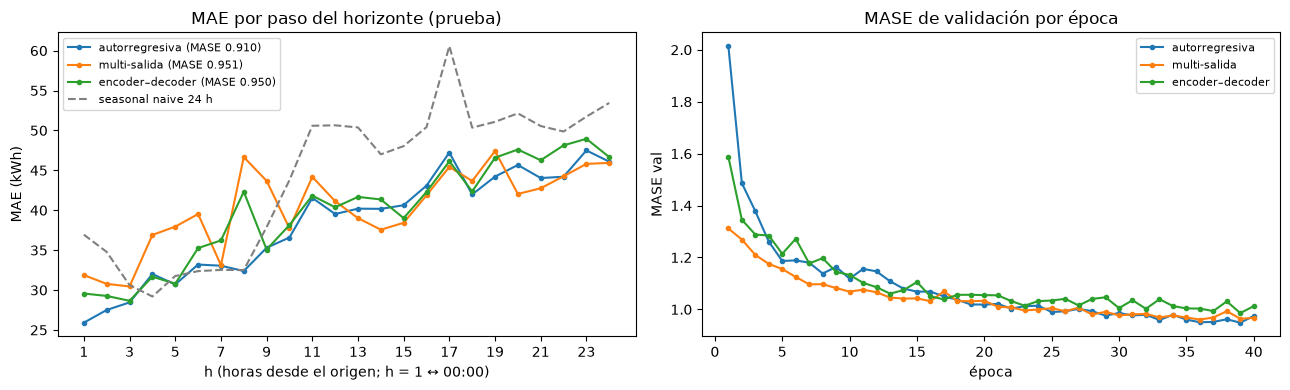

MAE (kWh) en h = 1, 6, 12, 24 y razón h24 / h1:
             1      6     12     24  h24/h1
LSTM-AR  25.91  33.19  39.53  46.09    1.78
LSTM-MO  31.87  39.52  41.14  45.93    1.44
Seq2Seq  29.56  35.26  40.37  46.66    1.58


In [24]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for nom, est in [('LSTM-AR', 'autorregresiva'), ('LSTM-MO', 'multi-salida'), ('Seq2Seq', 'encoder–decoder')]:
    e = error_por_paso(RESULTADOS[nom])
    axs[0].plot(e.index, e.values, marker='o', ms=3, label=f'{est} (MASE {METRICAS[nom]["MASE"]:.3f})')
    hh = HISTORIALES[nom]
    axs[1].plot(hh['epoca'], hh['MASE_val'], marker='o', ms=3, label=est)
e = error_por_paso(RESULTADOS['SeasonalNaive24'])
axs[0].plot(e.index, e.values, ls='--', color='gray', label='seasonal naive 24 h')
axs[0].set(title='MAE por paso del horizonte (prueba)', xlabel='h (horas desde el origen; h = 1 ↔ 00:00)',
           ylabel='MAE (kWh)', xticks=range(1, 25, 2)); axs[0].legend(fontsize=8)
axs[1].set(title='MASE de validación por época', xlabel='época', ylabel='MASE val'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'estrategias_multipaso.png'), dpi=130); plt.show()

paso = pd.DataFrame({n: error_por_paso(RESULTADOS[n]) for n in ['LSTM-AR', 'LSTM-MO', 'Seq2Seq']})
print('MAE (kWh) en h = 1, 6, 12, 24 y razón h24 / h1:')
print(pd.concat([paso.loc[[1, 6, 12, 24]].T, (paso.loc[24] / paso.loc[1]).rename('h24/h1')], axis=1).round(2))

### 5.5 Curvas de entrenamiento de los modelos propios

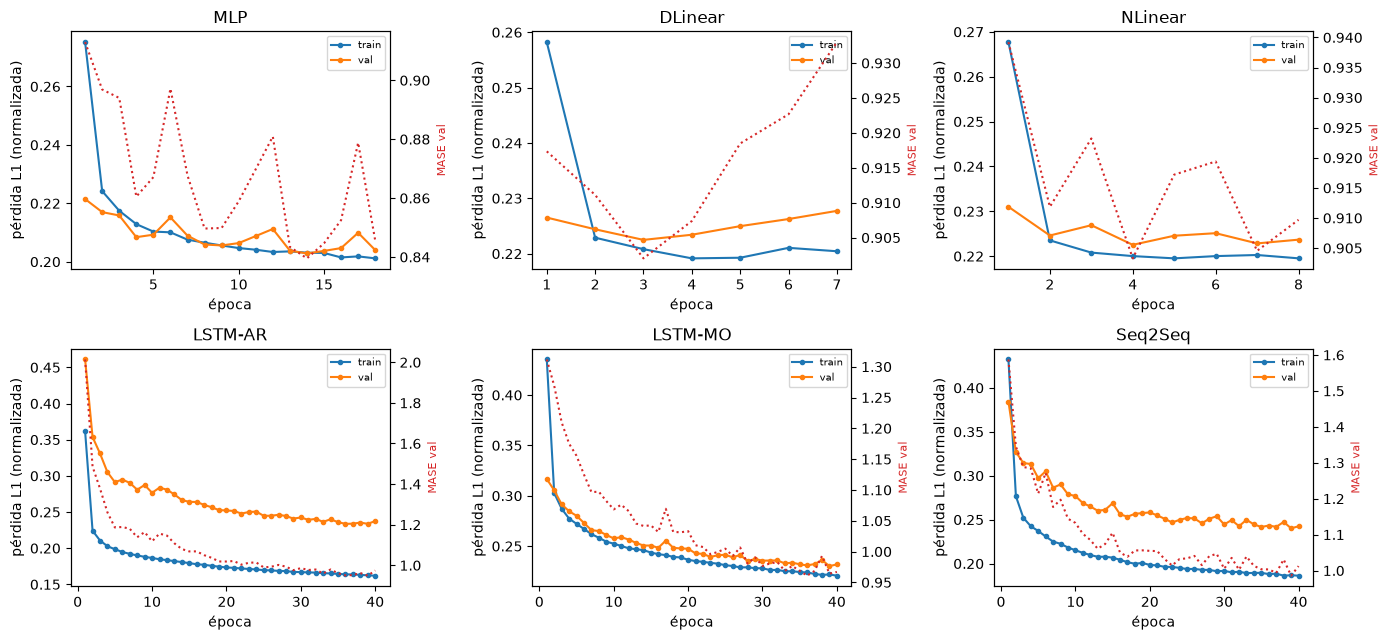

 modelo   L  H meses  norm    lr  batch  params  epocas  mejor_epoca  MAE_val  MASE_val  t_epoca_s  t_total_s  mem_pico_MB
    MLP 168 24  None serie 0.001    512  322328      18           14  31.6488    0.8395     0.4931     9.2004      56.7031
DLinear 168 24  None serie 0.005    512    8112       7            3  35.0125    0.9020     0.4148     3.0255      56.7656
NLinear 168 24  None serie 0.005    512    4056       8            4  35.0675    0.9033     0.3630     3.0220      56.7812
LSTM-AR 168 24  None serie 0.001    512   52545      40           36  36.2936    0.9504     6.2640   259.6116    2637.2188
LSTM-MO 168 24  None serie 0.001    512   58648      40           39  36.9640    0.9642     5.4285   225.1090    2512.6250
Seq2Seq 168 24  None serie 0.001    512  105025      40           39  38.1589    0.9858     6.6615   275.3996    2723.0000


In [25]:
propios = ['MLP', 'DLinear', 'NLinear', 'LSTM-AR', 'LSTM-MO', 'Seq2Seq']
fig, axs = plt.subplots(2, 3, figsize=(14, 6.5), sharex=False)
for ax, nom in zip(axs.ravel(), propios):
    hh = HISTORIALES[nom]
    ax.plot(hh['epoca'], hh['loss_train'], marker='o', ms=3, label='train')
    ax.plot(hh['epoca'], hh['loss_val'], marker='o', ms=3, label='val')
    ax2 = ax.twinx(); ax2.plot(hh['epoca'], hh['MASE_val'], color='C3', ls=':', label='MASE val')
    ax2.set_ylabel('MASE val', color='C3', fontsize=8)
    ax.set(title=nom, xlabel='época', ylabel='pérdida L1 (normalizada)'); ax.legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'curvas_perdida_propios.png'), dpi=130); plt.show()

tabla_iter = pd.DataFrame(ITERACIONES)
tabla_iter.to_csv(os.path.join(REPORTS, 'tabla_iteraciones.csv'), index=False)
print(tabla_iter[['modelo', 'L', 'H', 'meses', 'norm', 'lr', 'batch', 'params', 'epocas', 'mejor_epoca',
                  'MAE_val', 'MASE_val', 't_epoca_s', 't_total_s', 'mem_pico_MB']].round(4).to_string(index=False))

### Resultados parciales (baselines + modelos propios)

`tabla_comparativa()` arma la tabla de la sección 6 con todo lo que esté en `METRICAS`/`INFO` (ordenada por MASE) y
`guardar_pronosticos()` escribe el archivo de pronósticos de prueba `unique_id, ds, modelo, y_hat` (+ P10/P50/P90
cuando existan). Ambas se vuelven a llamar al final, cuando estén todos los modelos.

In [26]:
def tabla_comparativa():
    filas = []
    for nom, m in METRICAS.items():
        filas.append({'modelo': nom, **INFO[nom], **m})
    tab = pd.DataFrame(filas).sort_values('MASE').reset_index(drop=True)
    cols = ['modelo', 'familia', 'L', 'estrategia', 'covariables', 'params', 'params_entrenables',
            't_entrenamiento_s', 't_inferencia_s', 'hardware', 'MAE', 'RMSE', 'WAPE', 'MAPE', 'MASE', 'MASE_navidad']
    cols += [c for c in ('MASE_H168', 'pinball_esc', 'cobertura_80') if c in tab]
    return tab[cols]

def guardar_pronosticos(ruta=os.path.join(REPORTS, 'pronosticos_prueba.parquet')):
    cols = ['unique_id', 'ds', 'modelo', 'y_hat', 'p10', 'p50', 'p90']
    df = pd.concat([r[[c for c in cols if c in r]] for r in RESULTADOS.values()], ignore_index=True)
    df.to_parquet(ruta, index=False)
    print(f'{ruta}: {len(df):,} filas, {df["modelo"].nunique()} modelos')
    return df

tab = tabla_comparativa()
tab.to_csv(os.path.join(REPORTS, 'tabla_comparativa.csv'), index=False)
print(tab.round(4).to_string(index=False))
_ = guardar_pronosticos()

          modelo         familia   L      estrategia  covariables  params  params_entrenables  t_entrenamiento_s  t_inferencia_s            hardware      MAE     RMSE   WAPE   MAPE   MASE  MASE_navidad
             MLP  MLP y lineales 168    multi-salida         True  322328              322328             9.2004          0.0918  Apple M4 Pro · MPS  34.1428 174.2654 0.0663 0.0880 0.8201        1.3581
         LSTM-AR     Recurrentes 168  autorregresiva         True   52545               52545           259.6116          0.6073  Apple M4 Pro · MPS  38.3807 190.1837 0.0745 0.1017 0.9096        1.4889
         NLinear  MLP y lineales 168    multi-salida        False    4056                4056             3.0220          0.0551  Apple M4 Pro · MPS  37.6002 188.7348 0.0730 0.1053 0.9115        1.8372
         DLinear  MLP y lineales 168    multi-salida        False    8112                8112             3.0255          0.1009  Apple M4 Pro · MPS  37.8686 188.4802 0.0735 0.1075 0.9189     

../reports/pronosticos_prueba.parquet: 2,208,000 filas, 10 modelos


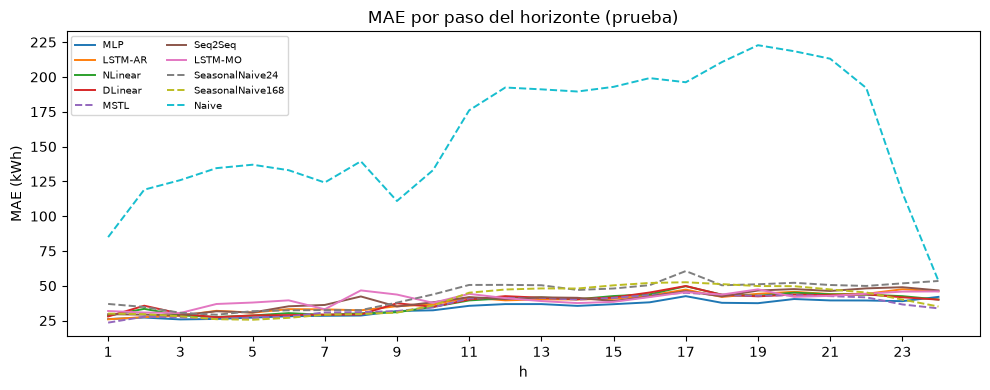

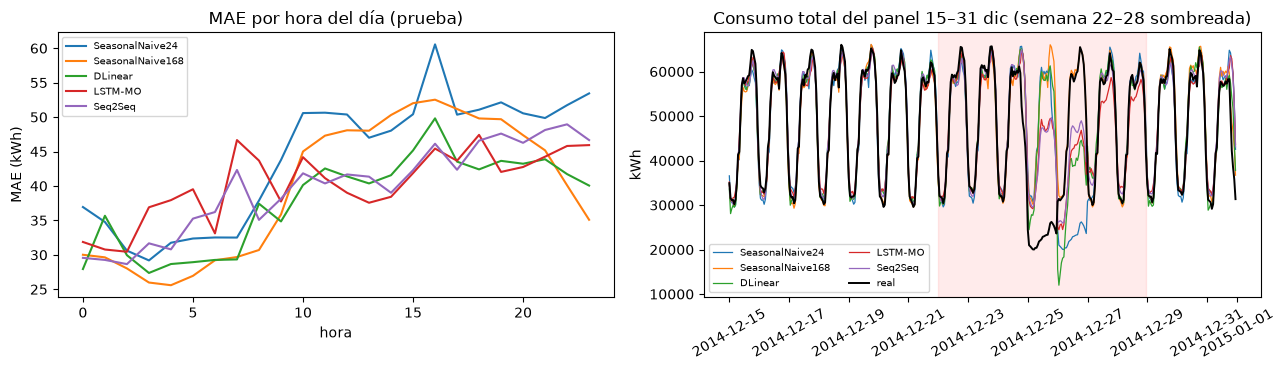

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))
for nom in tab['modelo']:
    e = error_por_paso(RESULTADOS[nom])
    ax.plot(e.index, e.values, lw=1.4, label=nom, ls='--' if INFO[nom]['familia'] == 'Baseline' else '-')
ax.set(title='MAE por paso del horizonte (prueba)', xlabel='h', ylabel='MAE (kWh)', xticks=range(1, 25, 2))
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'mae_por_paso.png'), dpi=130); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for nom in ['SeasonalNaive24', 'SeasonalNaive168', 'DLinear', 'LSTM-MO', 'Seq2Seq']:
    e = error_por_hora(RESULTADOS[nom]); axs[0].plot(e.index, e.values, label=nom)
    r = RESULTADOS[nom]; d = r[(r['ds'] >= '2014-12-15') & (r['ds'] <= '2015-01-01')]
    axs[1].plot(d.groupby('ds')['y_hat'].sum(), lw=0.9, label=nom)
axs[1].plot(d.groupby('ds')['y'].sum(), color='k', lw=1.4, label='real')
axs[1].axvspan(pd.Timestamp(NAVIDAD[0]), pd.Timestamp(NAVIDAD[1]), color='red', alpha=0.08)
axs[0].set(title='MAE por hora del día (prueba)', xlabel='hora', ylabel='MAE (kWh)'); axs[0].legend(fontsize=7)
axs[1].set(title='Consumo total del panel 15–31 dic (semana 22–28 sombreada)', ylabel='kWh'); axs[1].legend(fontsize=7, ncol=2)
axs[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(os.path.join(REPORTS, 'error_hora_navidad.png'), dpi=130); plt.show()

**MAPE y clientes de consumo bajo.** Se comparan MAPE y MASE por cliente para el mejor modelo propio:

In [28]:
mejor_propio = min(propios, key=lambda n: METRICAS[n]['MASE'])
r = RESULTADOS[mejor_propio]; pos = r['y'] > 0
mape_cli = ((r['y_hat'] - r['y']).abs()[pos] / r['y'][pos]).groupby(r['unique_id'][pos]).mean()
pc = metricas_por_cliente(r).assign(MAPE=mape_cli).sort_values('MAPE', ascending=False)
print(f'{mejor_propio}: MAPE global {METRICAS[mejor_propio]["MAPE"]:.1%} | mediana por cliente {pc["MAPE"].median():.1%}')
print('clientes con mayor MAPE:'); print(pc.head(5).round(3))
print(f'horas con y < 1 kWh en prueba: {(r["y"] < 1).mean():.2%}')

MLP: MAPE global 8.8% | mediana por cliente 7.3%
clientes con mayor MAPE:
              MAE    RMSE  media_y   MASE   MAPE
unique_id                                       
MT_036      8.887  13.119   38.424  0.679  0.391
MT_130     21.947  38.810   47.125  0.534  0.380
MT_354     19.806  33.927  108.913  1.089  0.236
MT_356      5.034   6.390   35.989  0.271  0.192
MT_162     38.809  59.601  293.695  0.485  0.183
horas con y < 1 kWh en prueba: 0.63%


---
## ⏳ Pendiente (Esteban) — a partir de aquí

Todo lo de arriba ya está listo y ejecutado. Lo que sigue usa las mismas piezas
(`panel`, `DF_LARGO`, `backtest`, `PronosticosPrecalculados`, `registrar`, `entrenar`, `tabla_comparativa`,
`guardar_pronosticos`). Ver `MEMORY.md` en la raíz del repo para el detalle.

### 5.6 Árboles: LightGBM global con rezagos (1–24, 168) y calendario

### 5.7 NeuralForecast: N-HiTS (o N-BEATS), TCN, PatchTST, TFT o iTransformer

### 5.8 Probabilístico: DeepAR (pinball loss y cobertura P10–P90)

### 5.9 Fundacional: Chronos-Bolt zero-shot

### 5.10 Iteraciones de hiperparámetros (L = 48/168/336, meses de historia 3/12/30, normalización, …)

### 5.11 Modelo local vs. global (10 clientes)

### 5.12 Reentrenamiento mensual (mejor DL y mejor baseline) y sensibilidad a la semilla (3 semillas)

## 6. Comparación de resultados (tabla final + 3 gráficas)

## 8. Discusión y análisis

In [29]:
# Al terminar: tabla final y archivo de pronósticos con TODOS los modelos.
# tab = tabla_comparativa(); tab.to_csv(os.path.join(REPORTS, 'tabla_comparativa.csv'), index=False)
# guardar_pronosticos()